---
title: "Report Total Fraud"
author: "Muhammad Arif Budiman"

format: typst
---

In [ ]:
#| echo: false
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [7]:
#| echo: false
df = pd.read_csv("dataset/credit_card_fraud_detection_2026.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 43 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   transaction_id               100000 non-null  str    
 1   customer_id                  100000 non-null  str    
 2   card_id                      100000 non-null  str    
 3   merchant_id                  100000 non-null  str    
 4   transaction_datetime         100000 non-null  str    
 5   transaction_amount           100000 non-null  float64
 6   merchant_category            100000 non-null  str    
 7   merchant_country             100000 non-null  str    
 8   transaction_hour             100000 non-null  int64  
 9   transaction_day_of_week      100000 non-null  str    
 10  card_present                 100000 non-null  int64  
 11  customer_age                 100000 non-null  int64  
 12  customer_gender              100000 non-null  str    
 13  customer_st

# EDA 
## Total Distribution Fraud

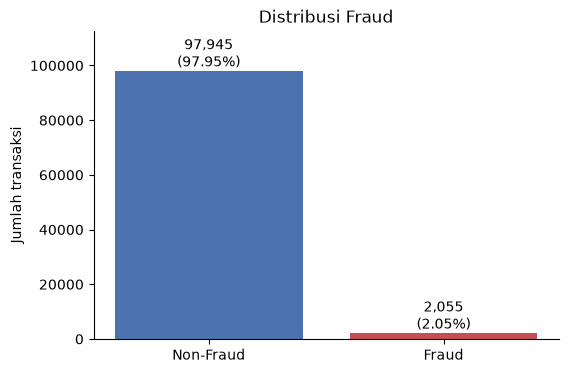

In [8]:
# | echo: false
# | label: fig-fraud-dist
# | fig-cap: "Distribusi transaksi fraud vs non-fraud"
counts = df['is_fraud'].value_counts().sort_index()
labels = ['Non-Fraud', 'Fraud']
pct = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(labels, counts.values, color=['#4C72B0', '#C44E52'])

for bar, n, p in zip(bars, counts.values, pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f"{n:,}\n({p:.2f}%)", ha='center', va='bottom')

ax.set_title("Distribusi Fraud")
ax.set_ylabel("Jumlah transaksi")
ax.spines[['top', 'right']].set_visible(False)
ax.set_ylim(0, counts.max() * 1.15)
plt.show()

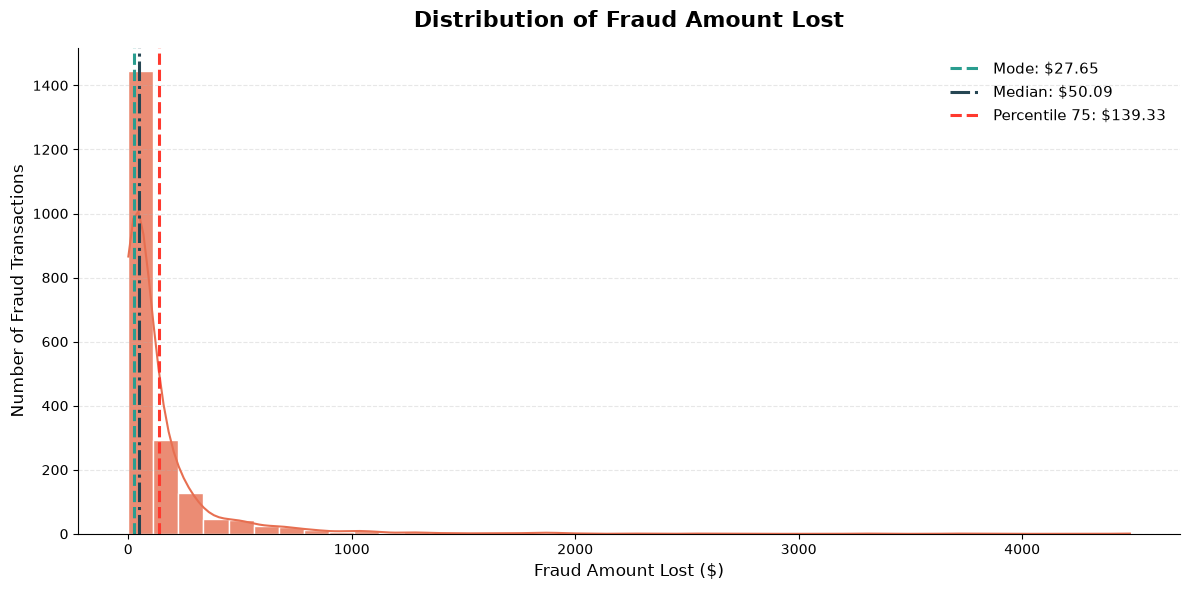

In [ ]:
fraud_data = df.loc[df["is_fraud"] == 1]

# Calculate statistics
median_loss = fraud_data["fraud_amount_lost"].median()
mode_loss = fraud_data["fraud_amount_lost"].mode().iloc[0]
max_loss = fraud_data['fraud_amount_lost'].quantile(0.75)

# Visualization
fig, ax = plt.subplots(figsize=(12, 6))

sns.histplot(
    data=fraud_data,
    x="fraud_amount_lost",
    bins=40,
    kde=True,
    color="#E76F51",
    edgecolor="white",
    alpha=0.8,
    ax=ax
)

# Mode line
ax.axvline(
    mode_loss,
    color="#2A9D8F",
    linestyle="--",
    linewidth=2.2,
    label=f"Mode: ${mode_loss:,.2f}"
)

# Median line
ax.axvline(
    median_loss,
    color="#264653",
    linestyle="-.",
    linewidth=2.2,
    label=f"Median: ${median_loss:,.2f}"
)

ax.axvline(
    max_loss,
    color="#FF392E",
    linestyle="--",
    linewidth=2.2,
    label=f"Percentile 75: ${max_loss:,.2f}"
)

# Titles and labels
ax.set_title(
    "Distribution of Fraud Amount Lost",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Fraud Amount Lost ($)", fontsize=12)
ax.set_ylabel("Number of Fraud Transactions", fontsize=12)

# Styling
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(
    loc="upper right",
    frameon=False,
    fontsize=11
)

sns.despine()
plt.tight_layout()
plt.show()